In [11]:
%% Homework 4
% Due: 
% Ely Dawson

In [10]:
%% We’ve talked about least-squares fitting, and we’ve talked about the Fourier transform, 
%% so it’s time for us to test both strategies out using the same data set. Here we’ll
%% use the automated pressure data from the Scripps Pier. Use the function that you wrote previously.

%% For 2021, we will use data records 70521 through 88190, since these are nearly evenly
%% spaced in time. There are 4 gaps, that we will need to fill.

In [24]:
function pier = pierdata_2021(pointRange, filepath)
% this function pulls all relevant years of SIO pier data 
% inputs:
%  - pointRange: range you want to look for. 
%         enter as range [     ]
%      Ex: [100 500]
%  - filepath: specific filepath for finding the pier data
% originally created for SIOC-221a HW1
% updated for use in HW4 Oct 2026
%   - changed code to view range rather than seperate years. 
%   - data only available 2004 - 2023. Hardcoded for 2021 currently.
%   - made a more elegant solution for adding the missing data points
% Ely J Dawson, 28 October 2026

    if nargin < 2 || isempty(filepath)
        filepath = pwd;
    end

    filename = fullfile(filepath, 'scripps_pier-2021.nc');

    time = double(ncread(filename, 'time'));
    temp = double(ncread(filename, 'temperature'));
    pres = double(ncread(filename, 'pressure'));

    % Sort chronologically
    [time, idx] = sort(time(:));
    temp = temp(:);
    pres = pres(:);
    temp = temp(idx);
    pres = pres(idx);

    % Check and select the original measurement range
    validateattributes(pointRange, {'numeric'}, {'vector', 'numel', 2, 'integer', 'positive', '<=', numel(time)});

    assert(pointRange(1) <= pointRange(2), 'The first point must be less than or equal to the last point.');

    points = pointRange(1):pointRange(2);

    time = time(points);
    temp = temp(points);
    pres = pres(points);

    % Fill missing measurements on a 240-second grid
    pier.time = (time(1):240:time(end))';
    pier.t = interp1(time, temp, pier.time, 'linear');
    pier.p = interp1(time, pres, pier.time, 'linear');

    pier.dnum = datetime(pier.time, 'ConvertFrom', 'posixtime');
end

pier = pierdata_2021([70521 88190], '/Users/elydawson/SIO221a_Github_code_2026/data');

unique(diff(pier.time))

ans = 240

In [25]:
%% 1. Visual evaluation. 

% Plot the time series of pressure data from 2021, and examine
% the time increments between adjacent measurements. (You can do this in Matlab
% using the “diff” command or in python using “numpy.diff”, for example.) 

%% Are the data always uniformly spaced? 
% Before our correction, there were the 4 gaps. After our correction for those gaps, 
% we can see that the data is uniformly spaced at 240 seconds apart from each measurement

%% What is the increment between measurements?
% We can see from our second figure, that our increment is 240 seconds between measurements.

%% How long is the time record? 
% This time record spans a period from 16-Jul-2021 01:54:18 to 03-Sep-2021 04:06:18, or 49 days, 2 hours, and 12 minutes.

%% Are there other portions of the 2021 record that also have reliable uniform spacing?
% With my modification to the code, I can reliably do any portion of the data and always get 240 second spacing. 

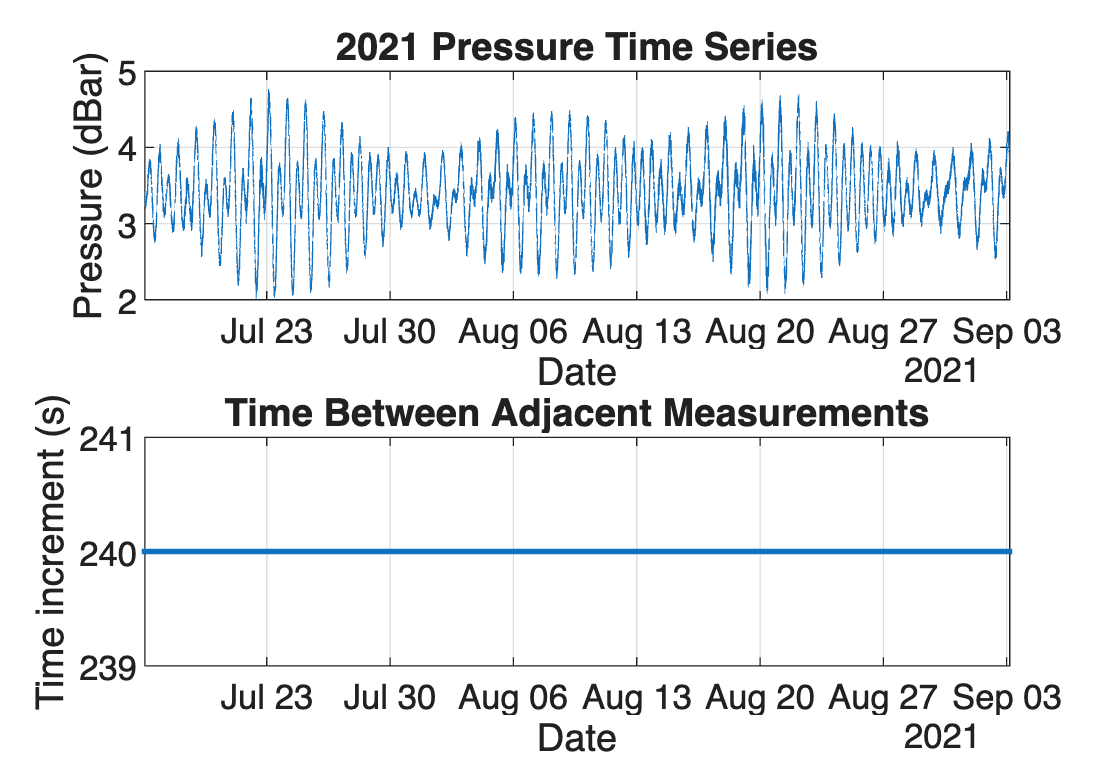

In [26]:
% Plot pressure time series
figure;
subplot(2,1,1)
plot(pier.dnum, pier.p)
xlabel('Date')
xlim([pier.dnum(1) pier.dnum(end)]);
ylabel('Pressure (dBar)')
title('2021 Pressure Time Series')
grid on

% Time increments between adjacent measurements
dt = diff(pier.time);

subplot(2,1,2)
plot(pier.dnum(2:end), dt, '.')
xlabel('Date')
xlim([pier.dnum(1) pier.dnum(end)]);
ylabel('Time increment (s)')
title('Time Between Adjacent Measurements')
grid on

In [27]:
%% 2. Least-squares fit.

% Least-squares fit a mean and 3 major tidal constituents to your data. 
% Plot the raw and model solution.

%% What is the mean, and what are the total amplitudes of the tidal constituents?
%% (Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.)


Fitted mean pressure: 3.4107 dBar
    Constituent    Amplitude_dBar
    ___________    ______________

       "M2"           0.49948    
       "S2"           0.20156    
       "K1"           0.36498    



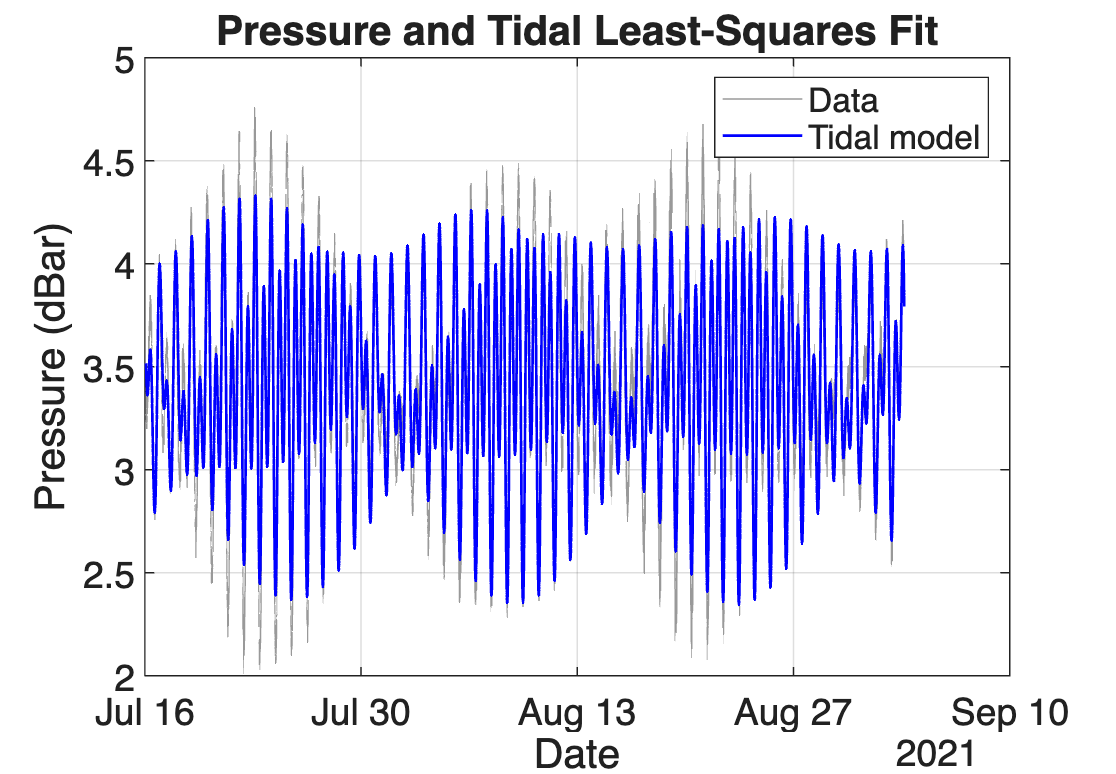

In [28]:
% Time in hours
t = (pier.time - pier.time(1))/3600;
p = pier.p;

% Tidal periods (hours): M2, S2, K1
names = ["M2"; "S2"; "K1"];
periods = [12.4206, 12, 23.9345];
omega = 2*pi./periods;

% Model: mean + sine and cosine for each constituent
A = [ones(size(t)), cos(t*omega), sin(t*omega)];

% Fit using finite pressure measurements
good = isfinite(p);
coef = A(good,:) \ p(good);
pfit = A*coef;

% Mean and total constituent amplitudes
meanPressure = coef(1);
amplitudes = sqrt(coef(2:4).^2 + coef(5:7).^2);

fprintf('Fitted mean pressure: %.4f dBar\n', meanPressure)
disp(table(names, amplitudes, 'VariableNames', {'Constituent', 'Amplitude_dBar'}))

% Plot data and fitted model
figure;
plot(pier.dnum, p, 'Color', [0.6 0.6 0.6])
hold on
plot(pier.dnum, pfit, 'b', 'LineWidth', 1)
xlabel('Date')
ylabel('Pressure (dBar)')
title('Pressure and Tidal Least-Squares Fit')
legend('Data', 'Tidal model')
grid on